## Data Pre-Processing


In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

pd.pandas.set_option("display.max_columns", None)

df = pd.read_csv(r"EasyVisa.csv")

print(df.shape)

(25480, 12)


## Data Cleaning
- handling missing values
- handling duplicates
- check data type
- understand the dataset

In [48]:
## Check null values
features_with_na = [features for features in df.columns if df[features].isnull().sum() >= 1]
for feature in features_with_na:
    print(feature,np.round(df[feature].isnull().mean()*100,5), '%missing values')

In [49]:
features_with_na

[]

There is no null values in the dataset

## Other Data cleaning steps
- Handling Duplicates

In [50]:
df.duplicated().sum()

0

In [51]:
## remove case_id
df.drop('case_id', inplace=True, axis=1)

## Feature Engineering
- feature extraction

In [52]:
df.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


In [53]:
## year ko normalize
from datetime import date

todays_date = date.today()
current_year = todays_date.year

In [54]:
current_year

2026

In [55]:
## subtract current year with year of estab to get company's age

df['company_age'] = current_year-df['yr_of_estab']

In [56]:
df.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status,company_age
0,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied,19
1,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified,24
2,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied,18
3,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied,129
4,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified,21


In [57]:
df.drop('yr_of_estab', inplace=True, axis=1)

In [58]:
df.head()

,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status,company_age
0,Asia,High School,N,N,14513,West,592.2029,Hour,Y,Denied,19
1,Asia,Master's,Y,N,2412,Northeast,83425.6500,Year,Y,Certified,24
2,Asia,Bachelor's,N,Y,44444,West,122996.8600,Year,Y,Denied,18
3,Asia,Bachelor's,N,N,98,West,83434.0300,Year,Y,Denied,129
4,Africa,Master's,Y,N,1082,South,149907.3900,Year,Y,Certified,21


## Types of Features

In [59]:
# Numeric Features
num_features = [feature for feature in df.columns if df[feature].dtype != 'O']
print('Num of Numerical features: ', len(num_features))

# Categorical Features
cat_features = [feature for feature in df.columns if df[feature].dtype == 'O']
print('Num of Categorical features: ', len(cat_features))

# Discrete Features
discrete_features = [feature for feature in num_features if len(df[feature].unique()) <=25]
print('Num of Discrete features: ', len(discrete_features))

# Continuous Features
continuous_features = [feature for feature in num_features if feature not in discrete_features]
print('Num of Continuous Features: ', len(continuous_features))

Num of Numerical features:  3
Num of Categorical features:  8
Num of Discrete features:  0
Num of Continuous Features:  3


## Split X and Y
- Split Dataframe to X and Y
- Here we set a variable X i.e, independent columns, and a variable Y i.e dependent column as the 'case_status' column

In [60]:
X = df.drop('case_status', axis=1)
Y = df['case_status']

In [61]:
# manual encoding target column
Y = np.where(Y=='Denied', 1,0)

In [62]:
Y

array([1, 0, 1, ..., 0, 0, 0])

## Feature Transformation

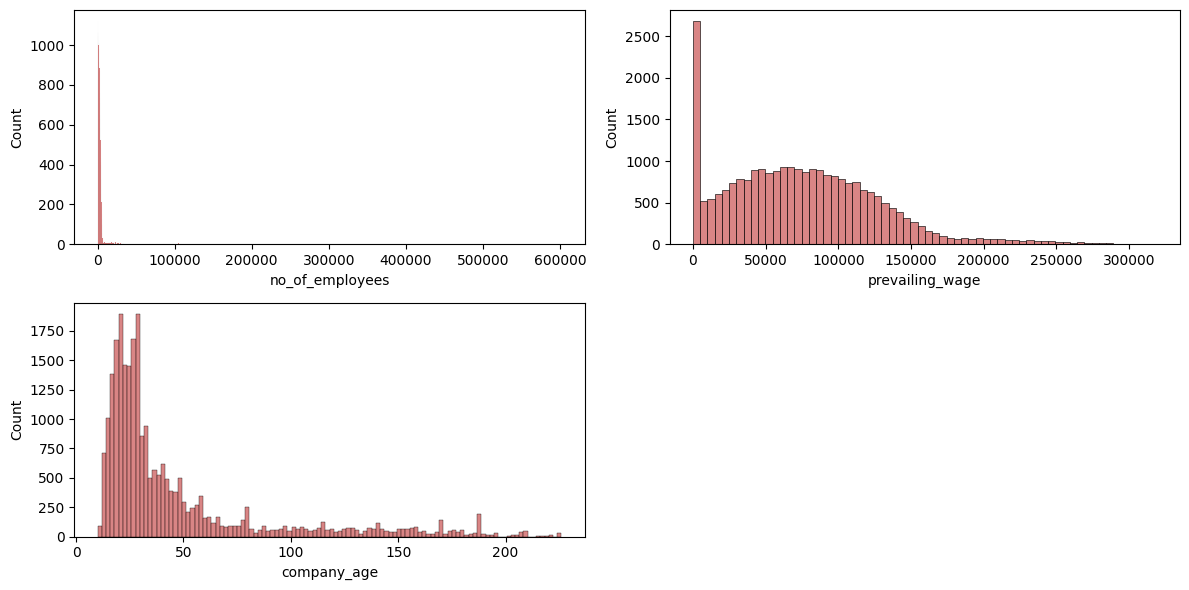

In [63]:
# distribution of data before scaling
plt.figure(figsize=(12,6))
for i,col in enumerate(['no_of_employees','prevailing_wage','company_age']):
    plt.subplot(2,2,i+1)
    sns.histplot(x=X[col], color='indianred')
    plt.xlabel(col)

plt.tight_layout()

- No of employees and Copmany age column is skewed
- Apply a power transform featurewise to make data more Gaussian-like.
Power transforms are a family of parametric, monotonic transformations that are applied to make data more Gaussian-like. This is useful for modeling issues related to heteroscedasticity (non-constant variance), or other situations where normality is desired.

Currently, PowerTransformer supports the Box-Cox transform and the Yeo-Johnson transform.

## Checking Skewness

## What is Skewness ?

- Skewness refers to a distortion or asymmetry that deviates from the symmetrical bell curve, or normal distribution, in a set of data. If the curve is shifted to the left or to the right, it is said to be skewed. Skewness can be quantified as a representation of the extent to which a given distribution varies from a normal distribution. A normal distribution has a skew of zero

In [64]:
X[continuous_features].skew(axis=0,skipna=True)

no_of_employees    12.265260
prevailing_wage     0.755776
company_age         2.037301
dtype: float64

- Positively skewed: company_age, no_of_employees.
- we can handle outliers and then check the skewness

## Apply Power Transformer to check if it can reduces the outliers

In [65]:
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')
transform_features = ['company_age', 'no_of_employees']
X_copy = pt.fit_transform(X[transform_features])

In [66]:
X_copy

array([[-0.95850606,  1.51729976],
       [-0.47081562,  0.03091211],
       [-1.08047911,  2.88507606],
       ...,
       [ 1.552921  , -0.41388512],
       [ 1.68577154, -0.11194883],
       [ 1.03193666,  0.21874168]])

In [67]:
X_copy = pd.DataFrame(X_copy, columns=transform_features)

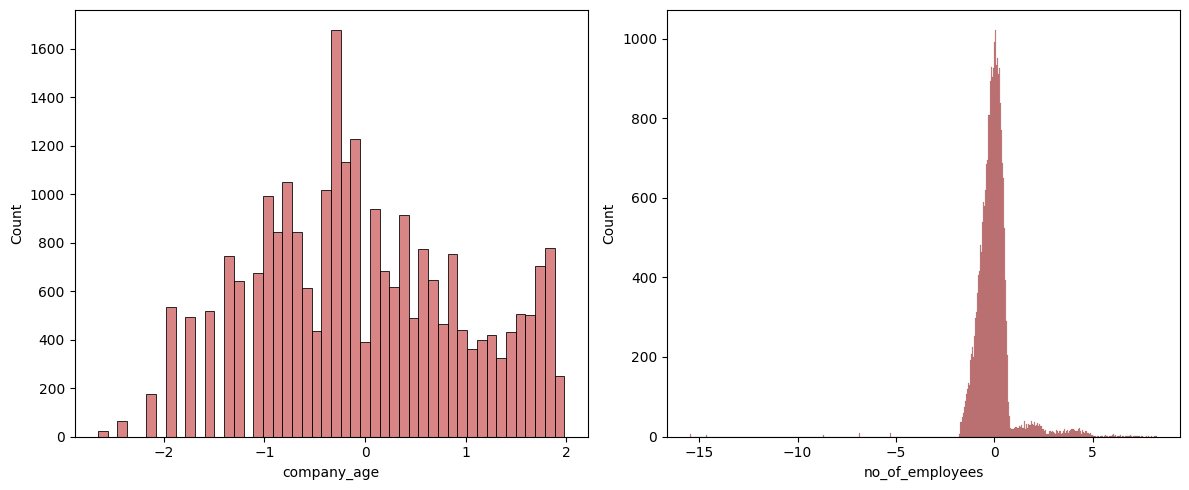

In [68]:
plt.figure(figsize=(12,5))
for i,col in enumerate(transform_features):
    plt.subplot(1,2,i+1)
    sns.histplot(x=X_copy[col], color='indianred')
    plt.xlabel(col)

plt.tight_layout()

Checking Skewness

In [69]:
X_copy.skew(axis=0, skipna=True)

company_age        0.120823
no_of_employees    0.399339
dtype: float64

- Here Yeo-johnson is used and it supports both positive or negative data for transformation.
- So power transformation with yeo-johnson can be used

In [70]:
# categorical features

for feature in cat_features:
    print(feature, ':', df[feature].nunique())

continent : 6
education_of_employee : 4
has_job_experience : 2
requires_job_training : 2
region_of_employment : 5
unit_of_wage : 4
full_time_position : 2
case_status : 2


## Feature Encoding and Scaling
One Hot Encoding for Columns which had lesser unique values and not ordinal

- One hot encoding is a process by which categorical variables are converted into a form that could be provided to ML algorithms to do a better job in prediction.
Ordinal Encoding for Columns which has many unique categories

- Ordinal encoding is used here as label encoder is supported for column transformer.
- Ordinal encoding is used for Ordinal Variable. Variable comprises a finite set of discrete values with a ranked ordering between values.
## Standard Scaler

- Standardize features by removing the mean and scaling to unit variance.
## Power Transformer

- Power transforms are a technique for transforming numerical input or output variables to have a Gaussian or more-Gaussian-like probability distribution.
Selecting number features for preprocessing

In [71]:
num_features = list(X.select_dtypes(exclude='object').columns)

In [72]:
num_features

['no_of_employees', 'prevailing_wage', 'company_age']

## Preprocessing using column transformer


In [73]:
or_columns = ['has_job_experience', 'requires_job_training','full_time_position','education_of_employee']
oh_columns = ['continent','unit_of_wage','region_of_employment']
transform_columns = ['no_of_employees','company_age']

from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_transformer = StandardScaler()
oh_transformer = OneHotEncoder()
ordinal_encoder = OrdinalEncoder()

transform_pipe = Pipeline(steps=[
    ('transformer', PowerTransformer(method='yeo-johnson'))
])

preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder", oh_transformer,oh_columns),
        ("OrdinalEncoder",ordinal_encoder,or_columns),
        ("Transformer",transform_pipe,transform_columns),
        ("StandarScaler", numeric_transformer, num_features)

    ]
)

In [74]:
X = preprocessor.fit_transform(X)

## Classification

In [75]:
from imblearn.combine import SMOTETomek, SMOTEENN

# Resampling the minority class. The strategy can be changed as required.
smt = SMOTEENN(random_state=42,sampling_strategy='minority' )
# Fit the model to generate the data.
X_res, Y_res = smt.fit_resample(X, Y)

  File "c:\Users\hpw\anaconda3\envs\visa_us\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "c:\Users\hpw\anaconda3\envs\visa_us\lib\subprocess.py", line 493, in run
    with Popen(*popenargs, **kwargs) as process:
  File "c:\Users\hpw\anaconda3\envs\visa_us\lib\subprocess.py", line 858, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\hpw\anaconda3\envs\visa_us\lib\subprocess.py", line 1327, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


## Train Test Split
- The train-test split procedure is used to estimate the performance of machine learning algorithms when they are used to make predictions on data not used to train the model.

- It is a fast and easy procedure to perform, the results of which allow you to compare the performance of machine learning algorithms.

In [76]:
from sklearn.model_selection import train_test_split
# separate dataset into train and test
X_train, X_test, Y_train, Y_test = train_test_split(X_res, Y_res, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((13644, 24), (3412, 24))

In [77]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay,\
                            precision_score,recall_score,f1_score,roc_auc_score,roc_curve
from xgboost import XGBClassifier
from catboost import CatBoostClassifier


In [78]:
def evaluate_clf(true,predicted):
    acc = accuracy_score(true, predicted)
    f1 = f1_score(true,predicted)
    precision = precision_score(true, predicted)
    recall = recall_score(true, predicted)
    roc_auc = roc_auc_score(true, predicted)
    return acc, f1, precision, recall, roc_auc

In [79]:
models = {
    "Random Forest": RandomForestClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "Logistic Regression": LogisticRegression(),
    "K-Neighbours Classifier": KNeighborsClassifier(),
    "XGBClassifier": XGBClassifier(),
    "CatBoost Classifier": CatBoostClassifier(verbose=False),
    "Support Vector Classifier": SVC(),
    "AdaBoost Classifier": AdaBoostClassifier()
}

In [82]:
# Create a function which can evaluate models and return a report 
def evaluate_models(X, y, models):
    '''
    This function takes in X and y and models dictionary as input
    It splits the data into Train Test split
    Iterates through the given model dictionary and evaluates the metrics
    Returns: Dataframe which contains report of all models metrics with cost
    '''
    # separate dataset into train and test
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
    
    models_list = []
    accuracy_list = []
    auc= []
    
    for i in range(len(list(models))):
        model = list(models.values())[i]
        model.fit(X_train, y_train) # Train model

        # Make predictions
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

        # Training set performance
        model_train_accuracy, model_train_f1,model_train_precision,\
        model_train_recall,model_train_rocauc_score=evaluate_clf(y_train ,y_train_pred)


        # Test set performance
        model_test_accuracy,model_test_f1,model_test_precision,\
        model_test_recall,model_test_rocauc_score=evaluate_clf(y_test, y_test_pred)

        print(list(models.keys())[i])
        models_list.append(list(models.keys())[i])

        print('Model performance for Training set')
        print("- Accuracy: {:.4f}".format(model_train_accuracy))
        print('- F1 score: {:.4f}'.format(model_train_f1)) 
        print('- Precision: {:.4f}'.format(model_train_precision))
        print('- Recall: {:.4f}'.format(model_train_recall))
        print('- Roc Auc Score: {:.4f}'.format(model_train_rocauc_score))

        print('----------------------------------')

        print('Model performance for Test set')
        print('- Accuracy: {:.4f}'.format(model_test_accuracy))
        accuracy_list.append(model_test_accuracy)
        print('- F1 score: {:.4f}'.format(model_test_f1))
        print('- Precision: {:.4f}'.format(model_test_precision))
        print('- Recall: {:.4f}'.format(model_test_recall))
        print('- Roc Auc Score: {:.4f}'.format(model_test_rocauc_score))
        auc.append(model_test_rocauc_score)
        print('='*35)
        print('\n')
        
    report=pd.DataFrame(list(zip(models_list, accuracy_list)), columns=['Model Name', 'Accuracy']).sort_values(by=['Accuracy'], ascending=False)
        
    return report

## Model Training


In [83]:
base_model_report = evaluate_models(X=X_res, y=Y_res, models=models)

Random Forest
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for Test set
- Accuracy: 0.9540
- F1 score: 0.9575
- Precision: 0.9577
- Recall: 0.9572
- Roc Auc Score: 0.9537


Decision Tree
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for Test set
- Accuracy: 0.9229
- F1 score: 0.9284
- Precision: 0.9332
- Recall: 0.9236
- Roc Auc Score: 0.9229


Gradient Boosting
Model performance for Training set
- Accuracy: 0.8860
- F1 score: 0.8944
- Precision: 0.8941
- Recall: 0.8946
- Roc Auc Score: 0.8852
----------------------------------
Model performance for Test set
- Accuracy: 0.8933
- F1 score: 0.9011
- Precision: 0.9040
- Recall: 0.8982
- Roc Auc Score: 0.8929


Logistic Regression
Model performance for Training 

## Results of all models

In [84]:
base_model_report

,Model Name,Accuracy
0,Random Forest,0.953986
4,K-Neighbours Classifier,0.941090
5,XGBClassifier,0.936401
6,CatBoost Classifier,0.928195
1,Decision Tree,0.922919
2,Gradient Boosting,0.893318
7,Support Vector Classifier,0.873681
8,AdaBoost Classifier,0.860785
3,Logistic Regression,0.737104


Here we can use Random forest for hyper parameter tuning
Define the parameter distribution for random forest

In [85]:
# Intialize few parameter for hyperparameter tuning

xgboost_params = {
    'max_depth': range(3,10,2),
    'min_child_weight': range(1,6,2)
}

rf_params = {
    "max_depth": [10,12,None,15,20],
    "max_features": ['sqrt','log2',None],
    "n_estimators": [10,50,100,200]
}

knn_params = {
    "algorithm": ['auto', 'ball_tree','kd_tree','brute'],
    "weights": ['uniform','distance'],
    "n_neighbors": [3,4,5,7,9],
}

In [86]:
# Models list for Hyperparameter tuning
randomcv_models = [
    ('XGBoost', XGBClassifier(), xgboost_params),
    ("RF", RandomForestClassifier(), rf_params),
    ("KNN", KNeighborsClassifier(), knn_params)
]

Create a function for model training and report which can be used in hyperparameter tuning loop

In [87]:
from sklearn.model_selection import RandomizedSearchCV

model_param = {}
for name, model, params in randomcv_models:
    random = RandomizedSearchCV(estimator=model,
                                param_distributions=params,
                                n_iter=100,
                                cv=3,
                                verbose=2,
                                n_jobs=-1)

    random.fit(X_res, Y_res)
    model_param[name] = random.best_params_


for model_name in model_param:
    print(f"--------Best params for {model_name}-----------")
    print(model_param[model_name])

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Fitting 3 folds for each of 60 candidates, totalling 180 fits
Fitting 3 folds for each of 40 candidates, totalling 120 fits
--------Best params for XGBoost-----------
{'min_child_weight': 1, 'max_depth': 9}
--------Best params for RF-----------
{'n_estimators': 100, 'max_features': 'sqrt', 'max_depth': None}
--------Best params for KNN-----------
{'weights': 'distance', 'n_neighbors': 4, 'algorithm': 'auto'}


## Retraining the model with best parameters

In [88]:
from sklearn.metrics import roc_auc_score,roc_curve
best_models = {
    "Random Forest Classifier": RandomForestClassifier(**model_param['RF']),
    "KNeighborsClassifier": KNeighborsClassifier(**model_param['KNN']),
    "XGBClassifier": XGBClassifier(**model_param['XGBoost'],n_jobs=-1),
}
tuned_report =evaluate_models(X=X_res, y=Y_res, models=best_models)

Random Forest Classifier
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for Test set
- Accuracy: 0.9540
- F1 score: 0.9574
- Precision: 0.9592
- Recall: 0.9556
- Roc Auc Score: 0.9538


KNeighborsClassifier
Model performance for Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for Test set
- Accuracy: 0.9719
- F1 score: 0.9743
- Precision: 0.9620
- Recall: 0.9870
- Roc Auc Score: 0.9705


XGBClassifier
Model performance for Training set
- Accuracy: 0.9994
- F1 score: 0.9995
- Precision: 0.9993
- Recall: 0.9996
- Roc Auc Score: 0.9994
----------------------------------
Model performance for Test set
- Accuracy: 0.9461
- F1 score: 0.9501
- Precision: 0.9521
- Recall: 0.9480
- Roc Auc Score: 0.9459




Tuned report


In [89]:
best_model = KNeighborsClassifier(**model_param['KNN'])
best_model = best_model.fit(X_train,Y_train)
y_pred = best_model.predict(X_test)
score = accuracy_score(Y_test,y_pred)
cr = classification_report(Y_test,y_pred)

print("FINAL MODEL 'KNN'")
print ("Accuracy Score value: {:.4f}".format(score))
print (cr)

FINAL MODEL 'KNN'
Accuracy Score value: 0.9719
              precision    recall  f1-score   support

           0       0.98      0.95      0.97      1566
           1       0.96      0.99      0.97      1846

    accuracy                           0.97      3412
   macro avg       0.97      0.97      0.97      3412
weighted avg       0.97      0.97      0.97      3412



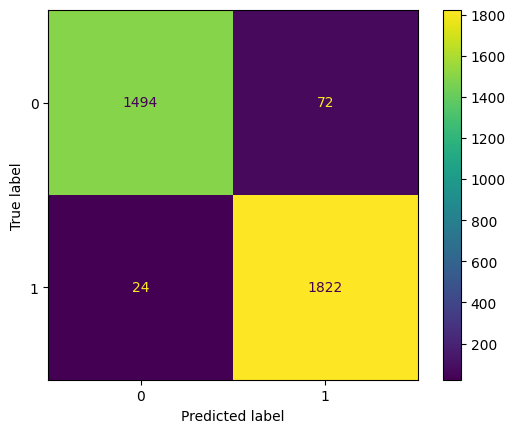

In [90]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(best_model, X_test, Y_test)